here we will annotate images using lines, circles, rectangles , text
# keep in mind that this is also applicable to video frames also

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from zipfile import ZipFile
from urllib.request import urlretrieve
import os

%matplotlib inline
import matplotlib

matplotlib.rcParams['figure.figsize'] = (9.0, 9.0)
from IPython.display import Image


In [7]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assets.....", end="")

    urlretrieve(url, save_path)

    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print("Done")
    except Exception as e:
        print("\nInvalid file.", e)

In [8]:
URL = r"https://www.dropbox.com/s/48hboi1m4crv1tl/opencv_bootcamp_assets_NB3.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), f"open_cv_bootcamp_assets_NB3.zip")

# Download if asset ZIP does not exists

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

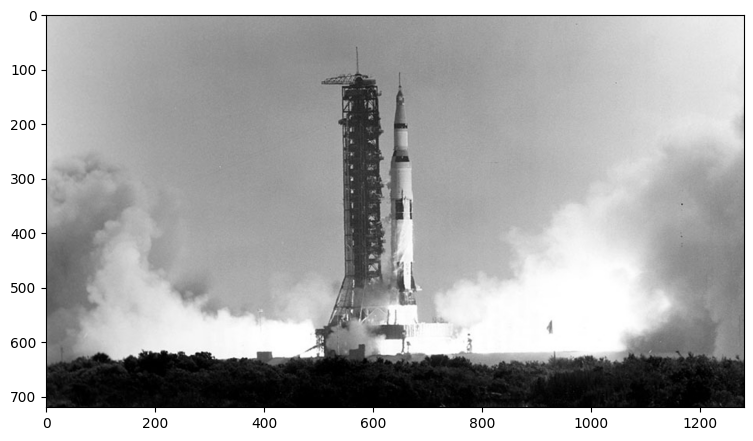

In [2]:
image = cv2.imread("Apollo_11_Launch.jpg", cv2.IMREAD_COLOR)

plt.imshow(image[:,:, ::-1])
plt.show()

# how to draw a line on a image
Let's start off by drawing a line on an image. We will use cv2.line function for this.

__Function Syntx__
img = cv2.line(img, pt1, pt2, color[, thickness[, lineType[, shift]]])
img: The output image that has been annotated.

The function has __4 required arguments:__

1. img: Image on which we will draw a line

2. pt1: First point(x,y location) of the line segment

3. pt2: Second point of the line segment

4. color: Color of the line which will be drawn

Other optional arguments that are important for us to know include:

1. thickness: Integer specifying the line thickness. Default value is 1.

2. lineType: Type of the line. Default value is 8 which stands for an 8-connected line. Usually, cv2.LINE_AA (antialiased or smooth line) is used for the lineType.

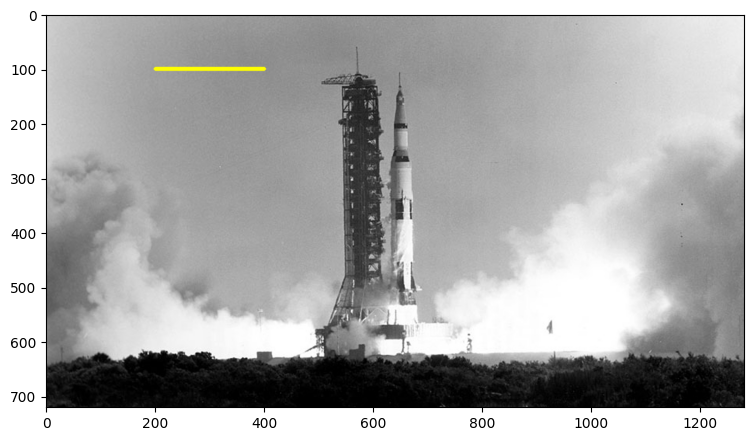

In [4]:
imageLine = image.copy()

# line starts from (200,100) and ends at (400, 100)
# the color of the line is yellow
# thickness of line is 5px
# line type is cv2.LINE_AA

cv2.line(imageLine, (200, 100), (400, 100), (0, 255, 255), thickness = 5, lineType= cv2.LINE_AA)

# Display the image
plt.imshow(imageLine[:,:,::-1])
plt.show()

# Drawing a circle


Drawing a Circle
Let's start off by drawing a circle on an image. We will use cv2.circle function for this.

__Functional syntx__

img = cv2.circle(img, center, radius, color[, thickness[, lineType[, shift]]])
img: The output image that has been annotated.

The function has 4 required arguments:

__img__: Image on which we will draw a line

__center__: Center of the circle

__radius__: Radius of the circle

__color__: Color of the circle which will be drawn

Next, let's check out the (optional) arguments which we are going to use quite extensively.

__thickness__: Thickness of the circle outline (if positive). If a negative value is supplied for this argument, it will result in a filled circle.

__lineType__: Type of the circle boundary. This is exact same as lineType argument in cv2.line

__When a thickness of -2 is passed into cv2.circle(), OpenCV will draw a completely filled-in solid circle.__


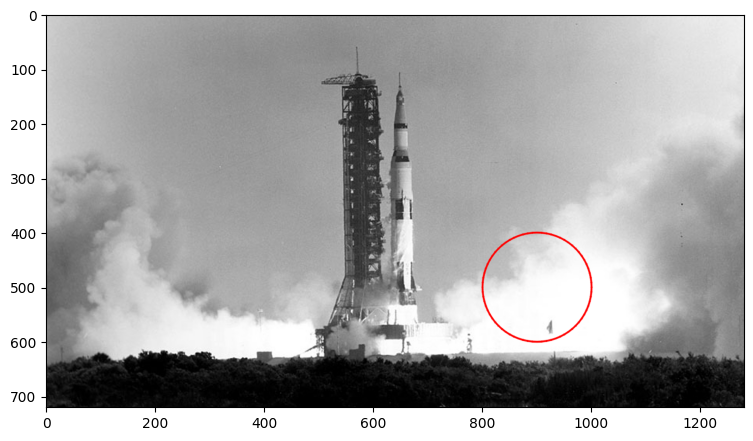

In [31]:
imageCircle = image.copy()

cv2.circle(imageCircle, (900, 500), 100, (0, 0, 255), thickness = 2, lineType=cv2.LINE_AA);

plt.imshow(imageCircle[:,:,::-1])
plt.show()

# Drawing a Rectangle
We will use cv2.rectangle function to draw a rectangle on an image. The function syntax is as follows.


__Functional syntx__

img = cv2.rectangle(img, pt1, pt2, color[, thickness[, lineType[, shift]]])

img: The output image that has been annotated.

The function has 4 required arguments:

1. img: Image on which the rectangle is to be drawn.

2. pt1: Vertex of the rectangle. Usually we use the top-left vertex here.

3. pt2: Vertex of the rectangle opposite to pt1. Usually we use the bottom-right vertex here.

4. color: Rectangle color

Next, let's check out the (optional) arguments which we are going to use quite extensively.

1. thickness: Thickness of the circle outline (if positive). If a negative value is supplied for this argument, it will result in a filled rectangle.

2. lineType: Type of the circle boundary. This is exact same as lineType argument in cv2.line



cv2.LINE_AA is an OpenCV line type parameter used in drawing functions (such as cv2.line(), cv2.rectangle(), cv2.circle(), and cv2.putText()) to render anti-aliased (smooth) shapes and text.

__What cv2.LINE_AA Does__

* Anti-aliasing: It blends the edge pixels of a line, curve, or character with the background color to eliminate jagged ("staircase") edges.
* Visual Quality: It makes diagonal lines, circles, and text look much smoother and higher-resolution compared to standard pixelated connection modes.
* Comparison with other line types:
	*  cv2.LINE_8: Standard 8-connected line (default in OpenCV).
	*  cv2.LINE_4: 4-connected line (faster, more jagged).
	*  cv2.LINE_AA: Anti-aliased line (smooth rendering using Gaussian/filtered edge approximation

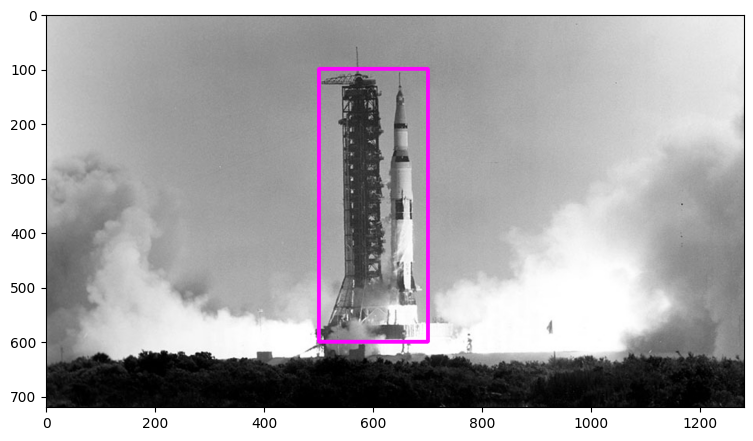

In [35]:
# Draw a rectangle (thickness is a positive integer)
imageRectangle = image.copy()

cv2.rectangle(imageRectangle, (500, 100), (700, 600), (255, 0, 255), thickness=5, lineType=cv2.LINE_8);

# Display the image
plt.imshow(imageRectangle[:,:,::-1])

plt.show()

# Adding Text
Finally, let's see how we can write some text on an image using __cv2.putText__ function.



__Functional syntx__

img = cv2.putText(img, text, org, fontFace, fontScale, color[, thickness[, lineType[, bottomLeftOrigin]]])

img: The output image that has been annotated.

The function has __6 required arguments:__

1. img: Image on which the text has to be written.

2. text: Text string to be written.

3. org: Bottom-left corner of the text string in the image.

4. fontFace: Font type

5. fontScale: Font scale factor that is multiplied by the font-specific base size.

6. color: Font color

Other optional arguments that are important for us to know include:

1. thickness: Integer specifying the line thickness for the text. Default value is 1.

2. lineType: Type of the line. Default value is 8 which stands for an 8-connected line. Usually, cv2.LINE_AA (antialiased or smooth line) is used for the lineType.


No, fontScale cannot be negative. It must be a positive floating-point number greater than zero (e.g., 0.5, 1.2, 2.0).

* When scale > 1: The text is magnified.
* When 0 < scale < 1: The text is minimized.
* When scale < 0: The text is mirrored or reversed.


# font thickness can't be negative

* __For Text (cv2.putText):__  Under the hood, OpenCV treats text as a collection of vector stroke lines (polylines) rather than a closed shape container. Because individual brush strokes cannot have an "interior" to fill, passing a negative value breaks the internal polyline rendering calculation.

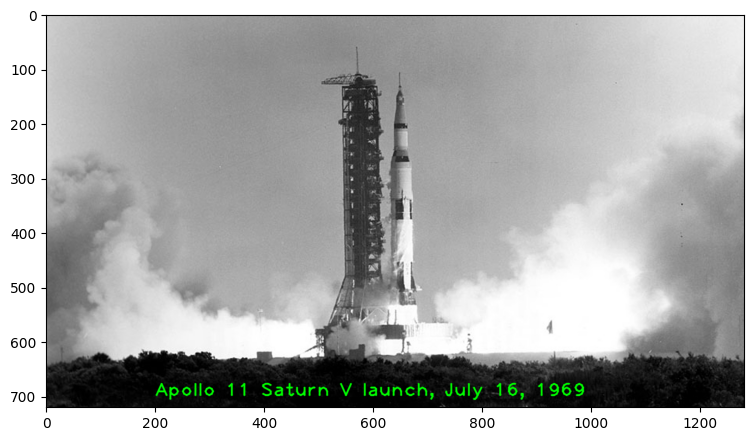

In [37]:
imageText = image.copy()
text = "Apollo 11 Saturn V launch, July 16, 1969"
fontScale = 2.3
fontFace = cv2.FONT_HERSHEY_PLAIN
fontColor = (0, 255, 0)
fontThickness = 2

cv2.putText(imageText, text, (200, 700), fontFace, fontScale, fontColor, fontThickness, cv2.LINE_AA);

plt.imshow(imageText[:,:,::-1])

plt.show()